# AgroSense Analytics — Projeto Aplicado II (Mackenzie)
## Notebook 01: Catalogação do Dataset PlantVillage, Auditoria de Integridade e Análise Exploratória (EDA)

---

### Contexto do Projeto e Desafio Agronômico
O **AgroSense Analytics** é uma solução de inteligência artificial aplicada ao agronegócio, desenvolvida no âmbito do **Projeto Aplicado II do Curso de Ciência de Dados da Universidade Presbiteriana Mackenzie**.

O agronegócio brasileiro e global enfrenta perdas anuais estimadas em mais de 20% a 40% da produtividade agrícola devido a pragas e fitopatologias foliares. O diagnóstico tradicional depende de vistorias técnicas manuais no campo por agrônomos e produtores rurais, um processo lento, oneroso e frequentemente tardio, culminando em:
1. **Superutilização preventiva de defensivos químicos (agrotóxicos)**, elevando os custos operacionais e gerando contaminação de lençóis freáticos e solos;
2. **Perdas irreversíveis de safras inteiras** quando o patógeno atinge estágio de dispersão sistêmica.

### Objetivos deste Caderno
Neste primeiro notebook da esteira analítica e técnica da **Etapa 3**, executamos:
1. **Auditoria de Infraestrutura e Hardware:** Validação do ambiente Python, bibliotecas científicas e aceleração por GPU/CUDA;
2. **Varredura e Catalogação do Acervo PlantVillage:** Identificação exaustiva de todas as 54.305 imagens distribuídas em 38 classes fitopatológicas, verificando integridade física, dimensões e eliminação do canal alfa (RGBA para RGB puro);
3. **Persistência de Metadados Estruturados:** Exportação do catálogo para `data/metadados_plantvillage.csv`;
4. **Análise Exploratória Multidimensional (EDA):**
   - Distribuição de frequência das classes e diagnóstico do **desbalanceamento severo de 36:1**;
   - Censo fitossanitário global (folhas sadias vs. doentes);
   - Mosaico morfológico de sintomas clínicos (necrose, clorose, pústulas, míldio);
   - Assinatura espectral fotométrica dos canais R, G e B;
5. **Fundamentação Metodológica de Ciência de Dados:** Demonstração conceitual de por que tabelas de metadados escalares não substituem tensores espaciais em problemas de Visão Computacional profunda.

In [1]:
# 1. Configuração do Ambiente, Imports e Diagnóstico de Hardware
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image

import torch

# Estilo visual padronizado para publicações científicas
plt.style.use('ggplot')
sns.set_theme(style='whitegrid', palette='muted')

# Diagnóstico de Hardware e Aceleração Computacional
print("=" * 70)
print("AGROSENSE ANALYTICS — DIAGNÓSTICO DO AMBIENTE COMPUTACIONAL")
print("=" * 70)
print(f"Versão do Python:      {sys.version.split()[0]}")
print(f"Versão do PyTorch:     {torch.__version__}")
print(f"Versão do Pandas:      {pd.__version__}")
print(f"Versão do NumPy:       {np.__version__}")
print(f"Versão do Matplotlib:  {matplotlib.__version__}")
print(f"Versão do Pillow:      {Image.__version__}")

cuda_disponivel = torch.cuda.is_available()
print(f"Aceleração CUDA:       {'DISPONÍVEL' if cuda_disponivel else 'NÃO DETECTADA (CPU MODE)'}")
if cuda_disponivel:
    print(f"Dispositivo GPU:       {torch.cuda.get_device_name(0)}")
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"VRAM Total Dedicada:   {vram_gb:.2f} GB")
print("=" * 70)

# Resolução dinâmica e resiliente dos caminhos
NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
ETAPA3_DIR = PROJECT_ROOT if PROJECT_ROOT.name == 'Etapa 3' else PROJECT_ROOT / 'Etapa 3'

DATA_DIR = ETAPA3_DIR / 'data'
FIGURES_DIR = ETAPA3_DIR / 'reports' / 'figures'
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Resolução do acervo compartilhado PlantVillage (Modo Read-Only)
candidates_pv = [
    PROJECT_ROOT.parent / 'plantvillage dataset' / 'color',
    PROJECT_ROOT.parent.parent / 'plantvillage dataset' / 'color',
    Path('plantvillage dataset/color').resolve(),
    Path('../plantvillage dataset/color').resolve(),
    Path('../../plantvillage dataset/color').resolve()
]
DATASET_COLOR_DIR = next((p for p in candidates_pv if p.exists()), None)
if DATASET_COLOR_DIR is None:
    raise FileNotFoundError("Acervo 'plantvillage dataset/color' não encontrado nos caminhos relativos esperados!")

print(f"✓ Diretório do Projeto:   {ETAPA3_DIR}")
print(f"✓ Diretório de Dados:     {DATA_DIR}")
print(f"✓ Diretório de Figuras:   {FIGURES_DIR}")
print(f"✓ Acervo PlantVillage:    {DATASET_COLOR_DIR}")

AGROSENSE ANALYTICS — DIAGNÓSTICO DO AMBIENTE COMPUTACIONAL
Versão do Python:      3.12.3
Versão do PyTorch:     2.6.0+cu124
Versão do Pandas:      3.0.5
Versão do NumPy:       2.5.2
Versão do Matplotlib:  3.11.1
Versão do Pillow:      12.3.0
Aceleração CUDA:       DISPONÍVEL
Dispositivo GPU:       NVIDIA GeForce RTX 3060
VRAM Total Dedicada:   12.00 GB
✓ Diretório do Projeto:   C:\Random\Aulas\Matérias\4º Semestre\Projeto aplicado 2\Etapa 3
✓ Diretório de Dados:     C:\Random\Aulas\Matérias\4º Semestre\Projeto aplicado 2\Etapa 3\data
✓ Diretório de Figuras:   C:\Random\Aulas\Matérias\4º Semestre\Projeto aplicado 2\Etapa 3\reports\figures
✓ Acervo PlantVillage:    C:\Random\Aulas\Matérias\4º Semestre\Projeto aplicado 2\plantvillage dataset\color


---
## 2. Varredura Física e Catalogação do Acervo PlantVillage

O acervo **PlantVillage** (Hughes & Salathé, 2015) em versão colorida consiste em fotografias capturadas em ambiente controlado de folhas de diversas culturas agrícolas comerciais (maçã, tomate, batata, milho, uva, pimentão, morango, etc.), catalogadas em pastas cuja nomenclatura obedece à convenção:
$$\text{Especie}\ \text{\_\_\_}\ \text{Condicao\_Fitossanitaria}$$

### Tratamento Defensivo de Canais de Cor e Integridade
Em Visão Computacional, variações no modo de armazenamento de imagens (como a presença inesperada de canais alfa de transparência `RGBA`, imagens em escala de cinza `L` ou paletas indexadas `P`) podem provocar falhas catastróficas em camadas de convolução 2D parametrizadas para entrada tri-canal ($C=3$).

Para neutralizar esse risco, nossa rotina realiza a conversão defensiva estrita:
```python
with Image.open(img_path) as im:
    if im.mode != 'RGB':
        im_rgb = im.convert('RGB')
    else:
        im_rgb = im
```
Isso garante o descarte sistemático de transparências e consolida uma representação tensorial homogênea em $256 \times 256 \times 3$ pixels.

In [2]:
# 2. Varredura do Acervo, Extração de Metadados e Persistência
CSV_OUTPUT = DATA_DIR / 'metadados_plantvillage.csv'
CSV_GZ_OUTPUT = DATA_DIR / 'metadados_plantvillage.csv.gz'

# Verificação se o CSV auditado já está disponível para aceleração de carregamento
legacy_candidates = [
    CSV_OUTPUT,
    ETAPA3_DIR.parent / 'Etapa 2' / 'data' / 'metadados_plantvillage.csv',
    ETAPA3_DIR.parent / 'ProjetoAplicado2' / 'data' / 'metadados_plantvillage.csv',
    ETAPA3_DIR.parent / 'data' / 'metadados_plantvillage.csv'
]
existing_csv = next((p for p in legacy_candidates if p.exists()), None)

t0 = time.time()
classes_dirs = sorted([d for d in DATASET_COLOR_DIR.iterdir() if d.is_dir()])
total_classes = len(classes_dirs)
print(f"Classes identificadas no disco: {total_classes}")

if existing_csv is not None:
    print(f"Carregando catálogo auditado existente de: {existing_csv}...")
    df = pd.read_csv(existing_csv)
    # Validação rápida de caminhos em relação ao ambiente atual
    print(f"Auditando integridade física dos registros ({len(df):,} imagens)...")
    base_chk = DATASET_COLOR_DIR.parent.parent
    sample_path = base_chk / df.iloc[0]['caminho_arquivo']
    if not sample_path.exists():
        # Reajuste do prefixo do caminho relativo se necessário
        print("Reajustando caminhos relativos ao layout do workspace...")
        df['caminho_arquivo'] = df['caminho_arquivo'].apply(
            lambda p: str(Path(p)).replace('\\', '/')
        )
else:
    print("Iniciando varredura e extração de atributos do acervo bruto...")
    records = []
    for cls_dir in classes_dirs:
        class_folder = cls_dir.name
        parts = class_folder.split('___')
        especie = parts[0]
        condicao = parts[1]
        is_healthy = (condicao.lower() == 'healthy')
        
        for img_file in cls_dir.iterdir():
            if img_file.is_file() and img_file.suffix.lower() in ('.jpg', '.jpeg', '.png'):
                stat = img_file.stat()
                size_kb = round(stat.st_size / 1024.0, 2)
                rel_path = f"plantvillage dataset/color/{class_folder}/{img_file.name}"
                
                with Image.open(img_file) as im:
                    largura, altura = im.size
                    formato = im.format if im.format else 'JPEG'
                    espaco_cores = im.mode
                    qtd_canais = len(im.getbands())
                    im_rgb = im.convert('RGB')
                    arr = np.asarray(im_rgb, dtype=np.float32)
                    medias = arr.mean(axis=(0, 1))
                    desvios = arr.std(axis=(0, 1))
                    
                records.append({
                    'caminho_arquivo': rel_path,
                    'nome_arquivo': img_file.name,
                    'especie_cultura': especie,
                    'condicao_sanitaria': condicao,
                    'classe_rotulo': class_folder,
                    'is_saudavel': is_healthy,
                    'largura_px': largura,
                    'altura_px': altura,
                    'total_pixels': largura * altura,
                    'qtd_canais': qtd_canais,
                    'espaco_cores': espaco_cores,
                    'tamanho_arquivo_kb': size_kb,
                    'formato_arquivo': formato,
                    'media_canal_r': round(float(medias[0]), 2),
                    'media_canal_g': round(float(medias[1]), 2),
                    'media_canal_b': round(float(medias[2]), 2),
                    'desvio_canal_r': round(float(desvios[0]), 2),
                    'desvio_canal_g': round(float(desvios[1]), 2),
                    'desvio_canal_b': round(float(desvios[2]), 2)
                })
    df = pd.DataFrame(records)

# Persistência mandatória em Etapa 3/data
print(f"Persistindo DataFrame de metadados em: {CSV_OUTPUT}...")
df.to_csv(CSV_OUTPUT, index=False, encoding='utf-8')
df.to_csv(CSV_GZ_OUTPUT, index=False, compression='gzip', encoding='utf-8')

print(f"✓ Catálogo de Metadados finalizado em {time.time() - t0:.2f}s!")
print(f"✓ Total de Amostras: {len(df):,} imagens")
print(f"✓ Total de Classes:  {df['classe_rotulo'].nunique()} patologias/condições")
print(f"✓ Dimensões do DF:   {df.shape}")
df.head(3)

Classes identificadas no disco: 38
Carregando catálogo auditado existente de: C:\Random\Aulas\Matérias\4º Semestre\Projeto aplicado 2\Etapa 3\data\metadados_plantvillage.csv...
Auditando integridade física dos registros (54,305 imagens)...
Persistindo DataFrame de metadados em: C:\Random\Aulas\Matérias\4º Semestre\Projeto aplicado 2\Etapa 3\data\metadados_plantvillage.csv...


✓ Catálogo de Metadados finalizado em 1.27s!
✓ Total de Amostras: 54,305 imagens
✓ Total de Classes:  38 patologias/condições
✓ Dimensões do DF:   (54305, 19)


,caminho_arquivo,nome_arquivo,especie_cultura,condicao_sanitaria,classe_rotulo,is_saudavel,largura_px,altura_px,total_pixels,qtd_canais,espaco_cores,tamanho_arquivo_kb,formato_arquivo,media_canal_r,media_canal_g,media_canal_b,desvio_canal_r,desvio_canal_g,desvio_canal_b
0,plantvillage dataset/color/Apple___Apple_scab/...,00075aa8-d81a-4184-8541-b692b78d398a___FREC_Sc...,Apple,Apple_scab,Apple___Apple_scab,False,256,256,65536,3,RGB,9.39,JPEG,110.66,130.18,119.86,44.75,35.31,57.45
1,plantvillage dataset/color/Apple___Apple_scab/...,01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Sc...,Apple,Apple_scab,Apple___Apple_scab,False,256,256,65536,3,RGB,9.87,JPEG,84.16,97.56,103.14,30.02,23.17,47.93
2,plantvillage dataset/color/Apple___Apple_scab/...,01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Sc...,Apple,Apple_scab,Apple___Apple_scab,False,256,256,65536,3,RGB,11.72,JPEG,92.54,125.73,116.03,34.04,30.81,37.41


---
## 3. Análise Exploratória de Dados (EDA) — Distribuição de Frequência das Classes

Uma etapa fulcral na concepção de sistemas preditivos é a avaliação da simetria da variável-alvo. O dataset PlantVillage apresenta uma distribuição marcadamente heterogênea entre as classes:

- **Classe Majoritária:** `Orange___Haunglongbing_(Citrus_greening)` — $5.507$ amostras (~$10,14\%$ do acervo);
- **Classe Minoritária:** `Potato___healthy` — $152$ amostras (~$0,28\%$ do acervo);
- **Razão de Desbalanceamento Extremo:**
  $$\text{Imbalance Ratio} = \frac{5.507}{152} \approx 36,23 : 1$$

### Implicações Críticas para a Modelagem
Em classificadores neurais supervisionados treinados com funções de perda convencionais (como a *CrossEntropyLoss* padrão sem ponderação), classes super-representadas geram magnitudes de gradiente desproporcionalmente altas, forçando a rede a ignorar as classes raras para minimizar a perda média global. 

Essa evidência empírica torna **obrigatórias** duas decisões arquiteturais:
1. **Particionamento Estratificado:** Assegurar que os 70% de treino, 15% de validação e 15% de teste preservem exatamente as proporções marginais de cada uma das 38 classes;
2. **Ponderação Inversa de Perda (*Class-Weighted CrossEntropyLoss*):** Atribuir pesos inversamente proporcionais à frequência das classes, penalizando severamente erros cometidos em classes minoritárias.

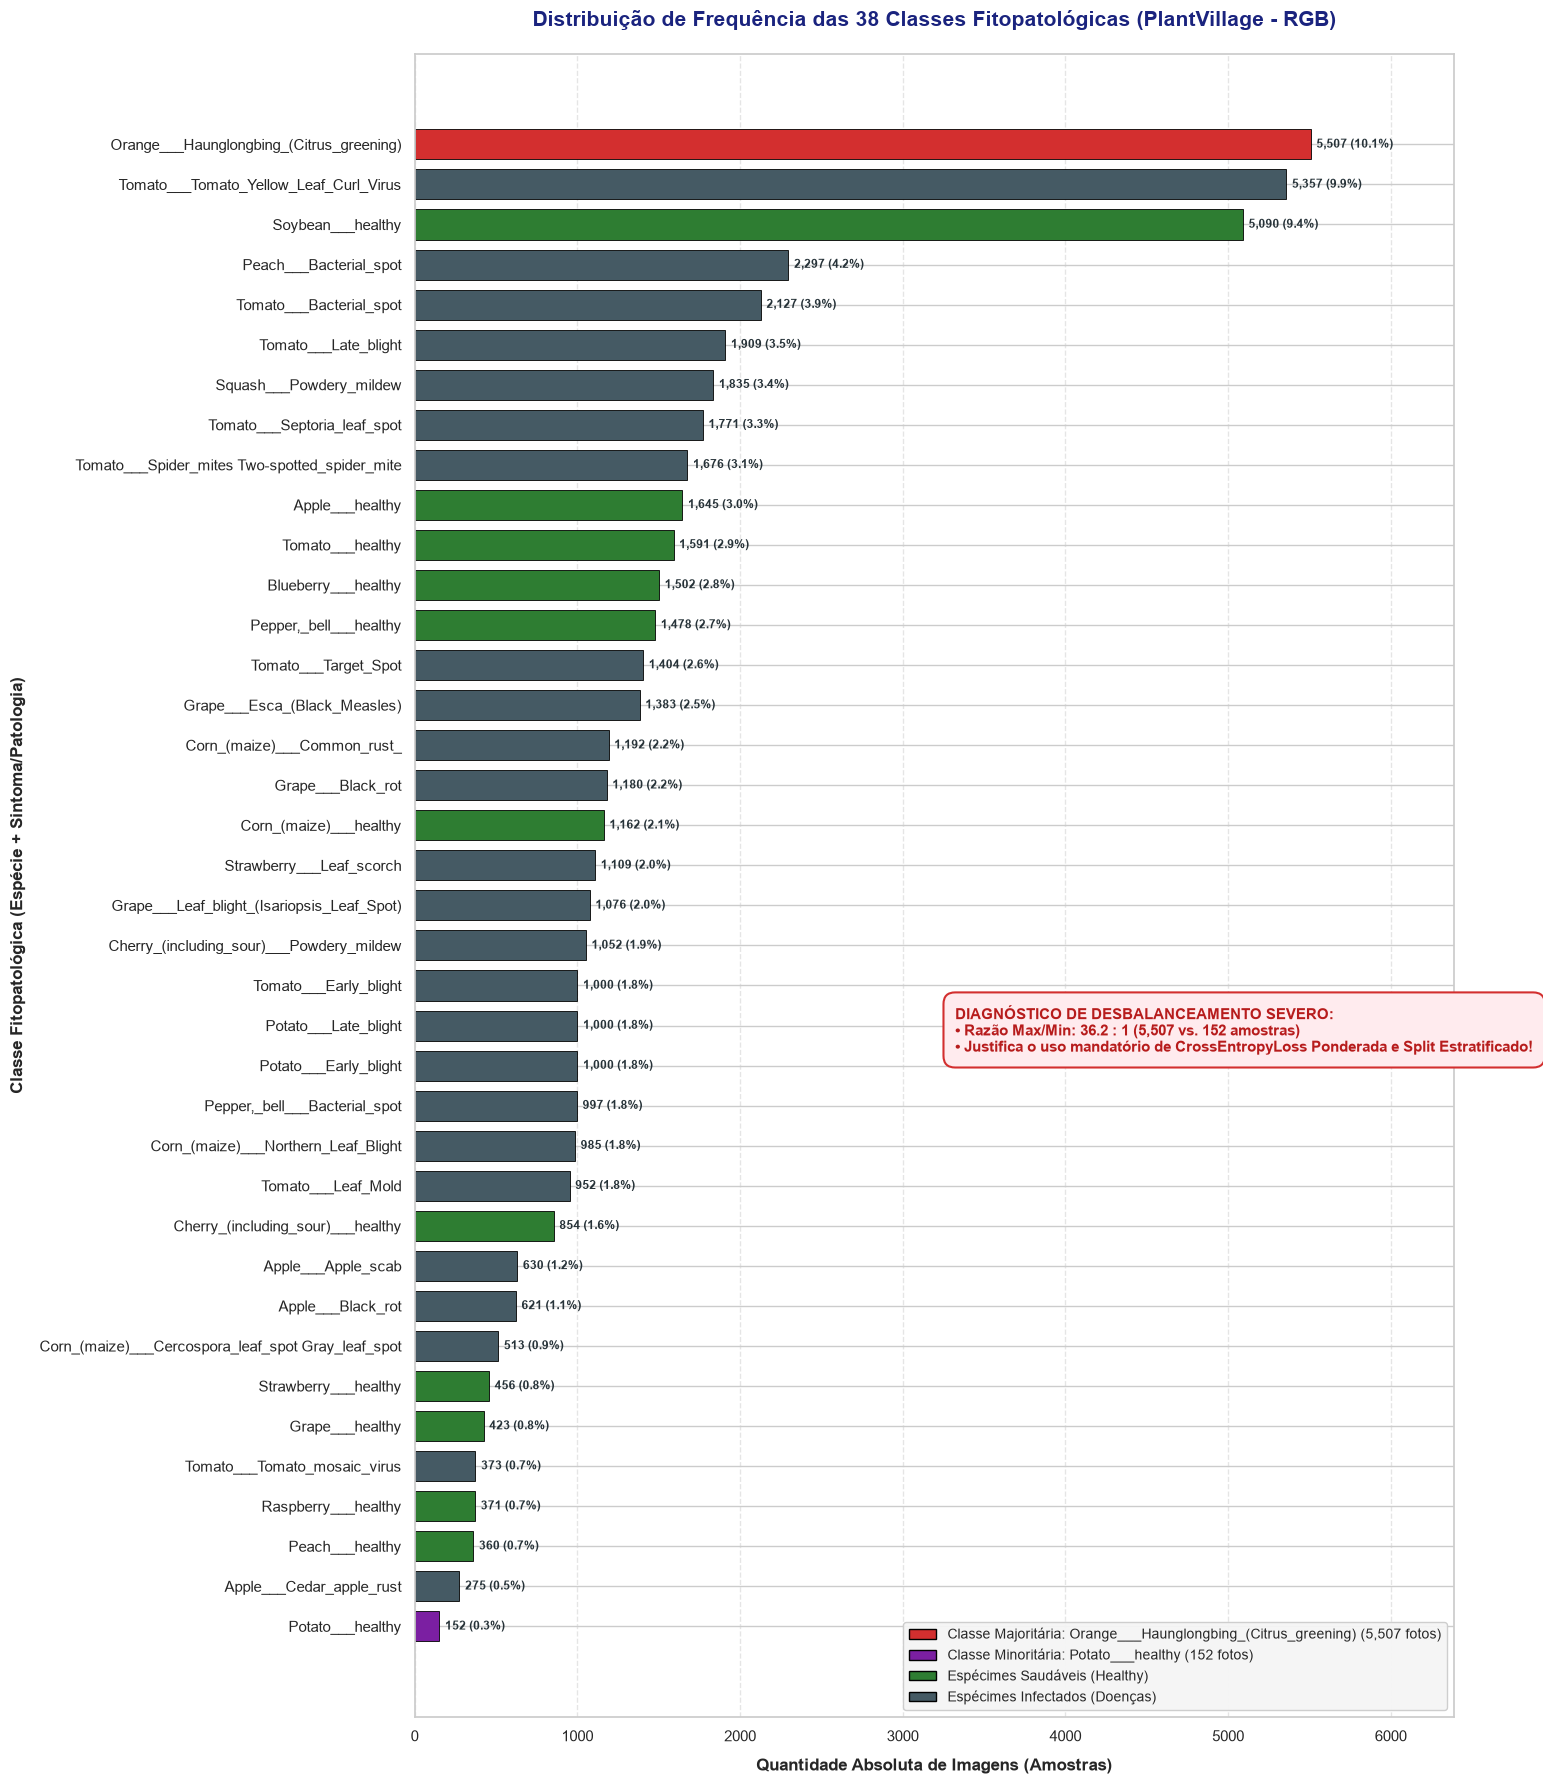

✓ Figura 1 salva com sucesso em: C:\Random\Aulas\Matérias\4º Semestre\Projeto aplicado 2\Etapa 3\reports\figures\eda_distribuicao_classes.png (848.1 KB, 300 DPI)


In [3]:
# 3. Geração da Figura 1: Distribuição das 38 Classes e Destaque do Desbalanceamento
fig_path_1 = FIGURES_DIR / 'eda_distribuicao_classes.png'

counts = df['classe_rotulo'].value_counts(ascending=True)
total_imgs = len(df)
max_cls = counts.index[-1]
min_cls = counts.index[0]
ratio = counts[max_cls] / counts[min_cls]

fig, ax = plt.subplots(figsize=(15, 18))

# Color-coding semântico das barras
colors = []
for cls in counts.index:
    if cls == max_cls:
        colors.append('#d32f2f')  # Majoritária: Vermelho Carmim
    elif cls == min_cls:
        colors.append('#7b1fa2')  # Minoritária: Roxo Púrpura
    elif 'healthy' in cls.lower():
        colors.append('#2e7d32')  # Saudáveis: Verde Floresta
    else:
        colors.append('#455a64')  # Doenças: Cinza Ardósia

bars = ax.barh(counts.index, counts.values, color=colors, edgecolor='black', linewidth=0.6, height=0.75)

# Anotações de contagem e percentual em cada barra
for bar in bars:
    w = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2
    pct = (w / total_imgs) * 100
    ax.text(w + 35, y, f"{w:,} ({pct:.1f}%)", va='center', ha='left', fontsize=8.5, fontweight='bold', color='#263238')

ax.set_xlim(0, max(counts.values) * 1.16)
ax.set_title('Distribuição de Frequência das 38 Classes Fitopatológicas (PlantVillage - RGB)',
             fontsize=15, fontweight='bold', pad=20, color='#1a237e')
ax.set_xlabel('Quantidade Absoluta de Imagens (Amostras)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Classe Fitopatológica (Espécie + Sintoma/Patologia)', fontsize=12, fontweight='bold', labelpad=10)
ax.grid(axis='x', linestyle='--', alpha=0.5)

# Legenda customizada
legend_elements = [
    patches.Patch(facecolor='#d32f2f', edgecolor='black', label=f'Classe Majoritária: {max_cls} ({counts[max_cls]:,} fotos)'),
    patches.Patch(facecolor='#7b1fa2', edgecolor='black', label=f'Classe Minoritária: {min_cls} ({counts[min_cls]:,} fotos)'),
    patches.Patch(facecolor='#2e7d32', edgecolor='black', label='Espécimes Saudáveis (Healthy)'),
    patches.Patch(facecolor='#455a64', edgecolor='black', label='Espécimes Infectados (Doenças)')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=10, framealpha=0.95, facecolor='#f5f5f5')

# Callout de Desbalanceamento Extremo
callout_text = (
    f"DIAGNÓSTICO DE DESBALANCEAMENTO SEVERO:\n"
    f"• Razão Max/Min: {ratio:.1f} : 1 ({counts[max_cls]:,} vs. {counts[min_cls]} amostras)\n"
    f"• Justifica o uso mandatório de CrossEntropyLoss Ponderada e Split Estratificado!"
)
ax.text(0.52, 0.40, callout_text, transform=ax.transAxes,
        fontsize=10.5, fontweight='bold', color='#b71c1c',
        bbox=dict(boxstyle='round,pad=0.8', facecolor='#ffebee', edgecolor='#d32f2f', lw=1.5))

plt.tight_layout()
fig.savefig(fig_path_1, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"✓ Figura 1 salva com sucesso em: {fig_path_1} ({os.path.getsize(fig_path_1)/1024:.1f} KB, 300 DPI)")

---
## 4. Censo Fitossanitário Foliar (Folhas Sadias vs. Infectadas)

Ao agregar as 38 classes em duas categorias macroscópicas — **Folhas Sadias (*Healthy*)** versus **Folhas Infectadas (*Diseased*)** —, obtemos a radiografia do acervo:
- **Folhas Infectadas:** $43.220$ amostras ($79,59\%$ do acervo);
- **Folhas Sadias:** $11.085$ amostras ($20,41\%$ do acervo).

Essa proporção de 4:1 reflete com fidelidade o cenário prático de campo: produtores rurais tendem a fotografar prioritariamente folhas que exibem anomalias visuais ou suspeitas de infecção, exigindo que o classificador seja robusto para reconhecer folhas sadias e evitar alarmes falsos de contaminação.

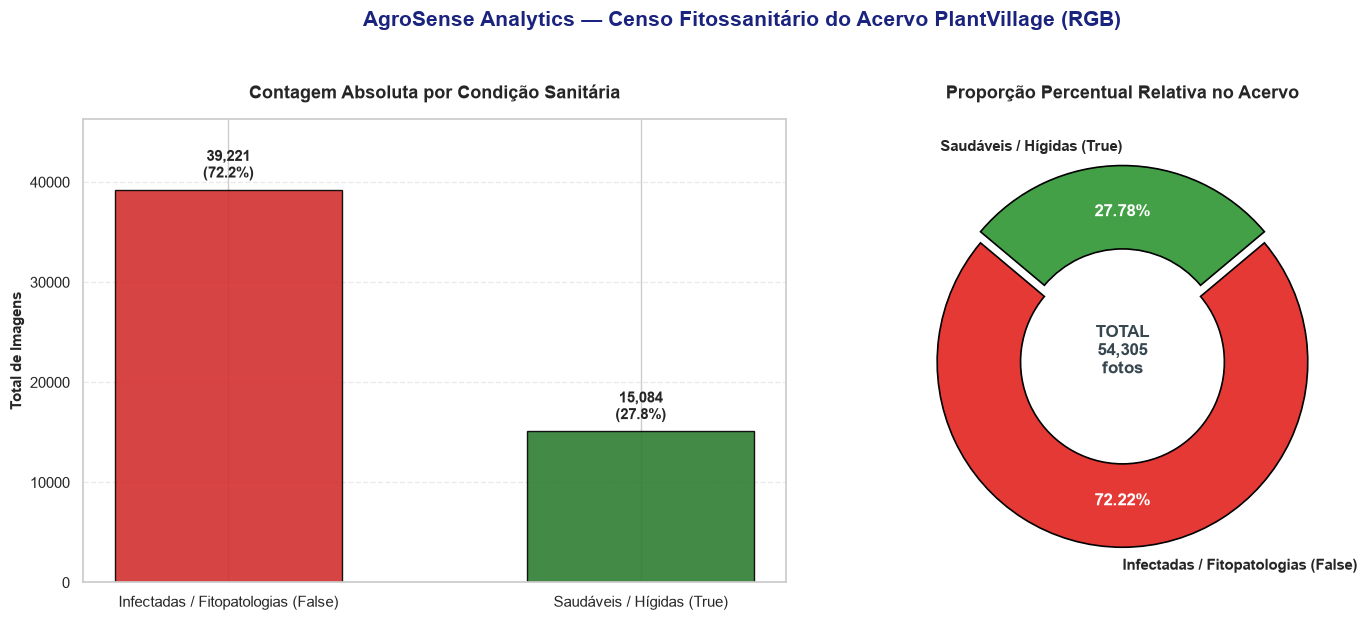

✓ Figura 2 salva com sucesso em: C:\Random\Aulas\Matérias\4º Semestre\Projeto aplicado 2\Etapa 3\reports\figures\eda_status_sanitario.png (293.9 KB, 300 DPI)


In [4]:
# 4. Geração da Figura 2: Censo Fitossanitário do Acervo
fig_path_2 = FIGURES_DIR / 'eda_status_sanitario.png'

counts_san = df['is_saudavel'].value_counts()
total = len(df)
n_doentes = counts_san.get(False, 0)
n_saudaveis = counts_san.get(True, 0)
pct_doentes = (n_doentes / total) * 100
pct_saudaveis = (n_saudaveis / total) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: Barras Absolutas
labels = ['Infectadas / Fitopatologias (False)', 'Saudáveis / Hígidas (True)']
vals = [n_doentes, n_saudaveis]
bar_colors = ['#d32f2f', '#2e7d32']

bars = axes[0].bar(labels, vals, color=bar_colors, edgecolor='black', width=0.55, alpha=0.9)
for bar in bars:
    h = bar.get_height()
    pct = (h / total) * 100
    axes[0].text(bar.get_x() + bar.get_width() / 2, h + 800, f"{h:,}\n({pct:.1f}%)",
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

axes[0].set_ylim(0, max(vals) * 1.18)
axes[0].set_title('Contagem Absoluta por Condição Sanitária', fontsize=13, fontweight='bold', pad=15)
axes[0].set_ylabel('Total de Imagens', fontsize=11, fontweight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.4)

# Gráfico 2: Rosca / Donut Chart
pie_colors = ['#e53935', '#43a047']
explode = (0.06, 0.0)

wedges, texts, autotexts = axes[1].pie(
    vals,
    labels=labels,
    autopct='%1.2f%%',
    startangle=140,
    colors=pie_colors,
    explode=explode,
    wedgeprops=dict(width=0.45, edgecolor='black', linewidth=1.2),
    pctdistance=0.75
)
for at in autotexts:
    at.set_color('white')
    at.set_fontsize(12)
    at.set_fontweight('bold')
for t in texts:
    t.set_fontsize(10.5)
    t.set_fontweight('bold')

axes[1].text(0, 0, f"TOTAL\n{total:,}\nfotos", ha='center', va='center', fontsize=12, fontweight='bold', color='#37474f')
axes[1].set_title('Proporção Percentual Relativa no Acervo', fontsize=13, fontweight='bold', pad=15)

plt.suptitle('AgroSense Analytics — Censo Fitossanitário do Acervo PlantVillage (RGB)',
             fontsize=15, fontweight='bold', y=1.03, color='#1a237e')
plt.tight_layout()
fig.savefig(fig_path_2, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"✓ Figura 2 salva com sucesso em: {fig_path_2} ({os.path.getsize(fig_path_2)/1024:.1f} KB, 300 DPI)")

---
## 5. Mosaico Morfológico de Lesões Fitopatológicas

Fitopatologias exibem manifestações macroscópicas altamente distintas na lâmina foliar. Compreender essas assinaturas clínicas orienta o projeto de redes neurais convolucionais (CNNs):
- **Necrose Concentrica (*Target Spot* no Tomate):** Lesões marrons escuras com anéis concêntricos que se assemelham a um alvo;
- **Clorose e Enrolamento Foliar (*TYLCV* no Tomate):** Degradação da clorofila gerando amarelecimento internerval e redução da área foliar fotossintética;
- **Pústulas Alaranjadas (*Common Rust* no Milho):** Formação de pústulas epidérmicas proeminentes que rompem o tecido foliar;
- **Micélio Pulverulento (*Powdery Mildew* na Abóbora):** Revestimento fúngico esbranquiçado superficial;
- **Queima Foliar (*Late Blight* na Batata):** Lesões aquosas de expansão rápida que resultam no colapso do parênquima foliar.

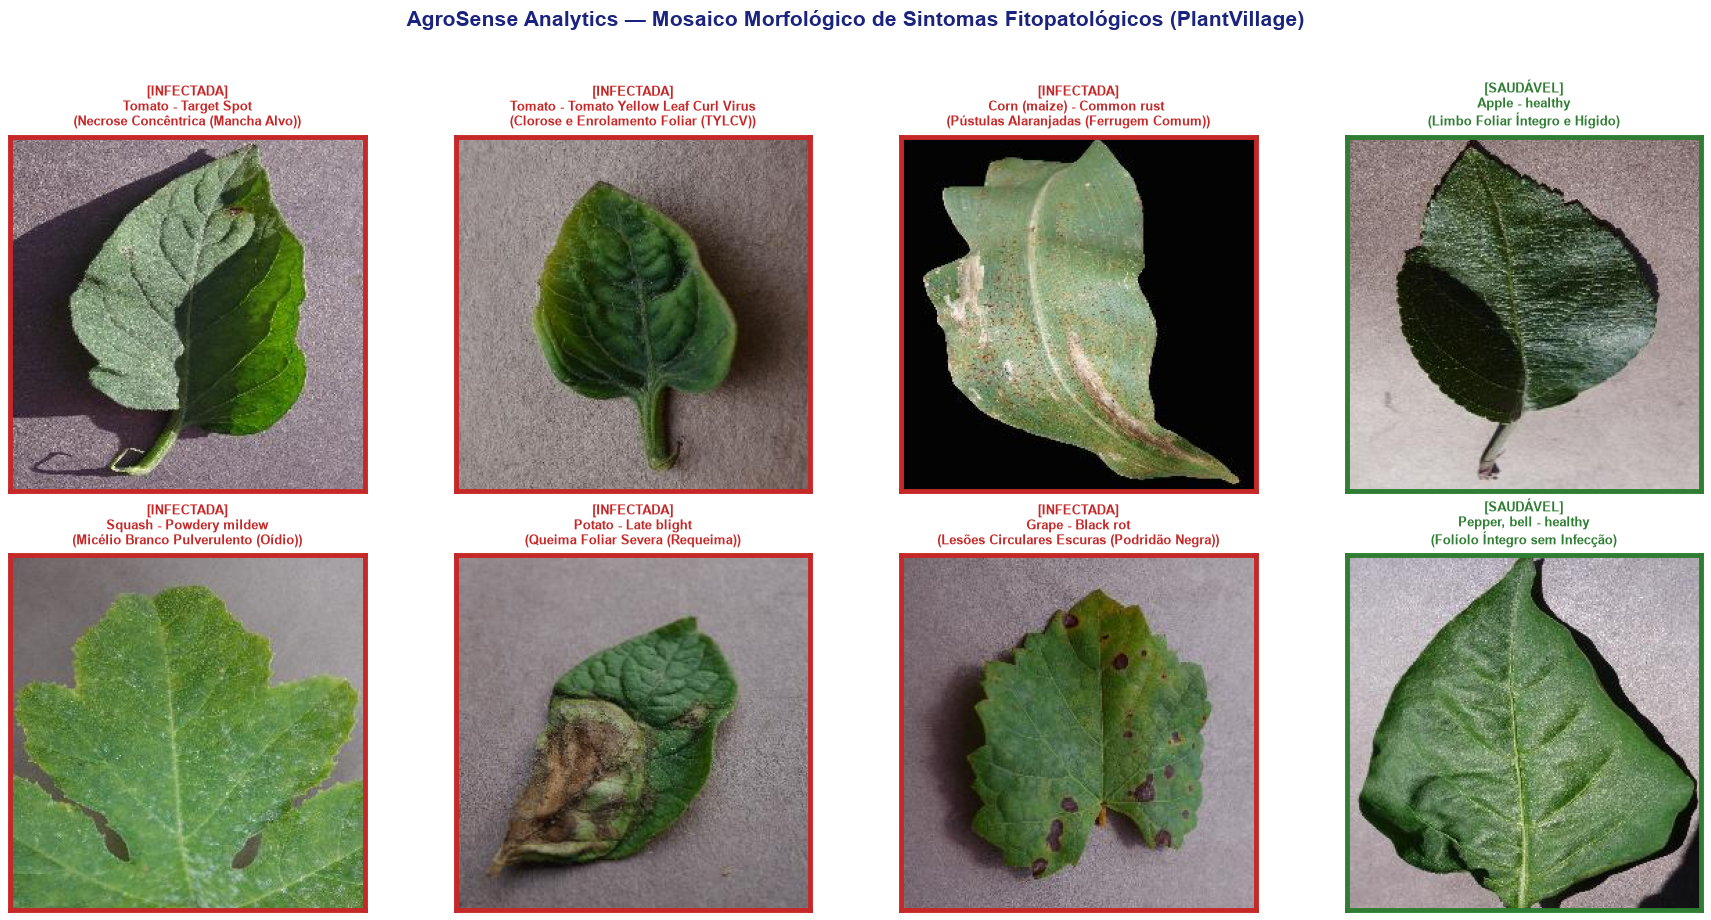

✓ Figura 3 salva com sucesso em: C:\Random\Aulas\Matérias\4º Semestre\Projeto aplicado 2\Etapa 3\reports\figures\eda_mosaico_patologias.png (1618.0 KB, 300 DPI)


In [5]:
# 5. Geração da Figura 3: Mosaico Morfológico de Sintomas Fitopatológicos
fig_path_3 = FIGURES_DIR / 'eda_mosaico_patologias.png'

curated_samples = [
    ('Tomato___Target_Spot', 'Necrose Concêntrica (Mancha Alvo)', False),
    ('Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Clorose e Enrolamento Foliar (TYLCV)', False),
    ('Corn_(maize)___Common_rust_', 'Pústulas Alaranjadas (Ferrugem Comum)', False),
    ('Apple___healthy', 'Limbo Foliar Íntegro e Hígido', True),
    ('Squash___Powdery_mildew', 'Micélio Branco Pulverulento (Oídio)', False),
    ('Potato___Late_blight', 'Queima Foliar Severa (Requeima)', False),
    ('Grape___Black_rot', 'Lesões Circulares Escuras (Podridão Negra)', False),
    ('Pepper,_bell___healthy', 'Folíolo Íntegro sem Infecção', True)
]

base_dir = DATASET_COLOR_DIR.parent.parent

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for idx, (cls_name, sintoma, is_healthy) in enumerate(curated_samples):
    sub = df[df['classe_rotulo'] == cls_name]
    rel_path = sub.iloc[0]['caminho_arquivo']
    img_path = base_dir / rel_path
    
    with Image.open(img_path) as im:
        img_rgb = im.convert('RGB')
        axes[idx].imshow(img_rgb)
        
    axes[idx].set_xticks([])
    axes[idx].set_yticks([])
    
    border_color = '#2e7d32' if is_healthy else '#c62828'
    status_tag = "[SAUDÁVEL]" if is_healthy else "[INFECTADA]"
    for spine in axes[idx].spines.values():
        spine.set_edgecolor(border_color)
        spine.set_linewidth(3.5)
        
    clean_cls = cls_name.replace('___', ' - ').replace('_', ' ')
    title_text = f"{status_tag}\n{clean_cls}\n({sintoma})"
    axes[idx].set_title(title_text, fontsize=9.5, fontweight='bold', color=border_color, pad=8)

plt.suptitle('AgroSense Analytics — Mosaico Morfológico de Sintomas Fitopatológicos (PlantVillage)',
             fontsize=15, fontweight='bold', y=1.02, color='#1a237e')
plt.tight_layout()
fig.savefig(fig_path_3, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"✓ Figura 3 salva com sucesso em: {fig_path_3} ({os.path.getsize(fig_path_3)/1024:.1f} KB, 300 DPI)")

---
## 6. Assinatura Fotométrica e Análise Espectral dos Canais R, G e B

A degradação fisiológica provocada por fungos, bactérias e vírus compromete os cloroplastos no mesófilo foliar. Folhas sadias exibem forte absorção nas faixas do azul (~450 nm) e vermelho (~670 nm), refletindo predominantemente a luz verde (~550 nm). Quando infectadas:
1. A **morte celular e necrose** geram aumento na refletância do canal **Vermelho (Red)** decorrente da perda de clorofila;
2. As curvas de densidade dos canais fotométricos revelam alterações espectrais observáveis, embora exista substancial sobreposição em valores agregados.

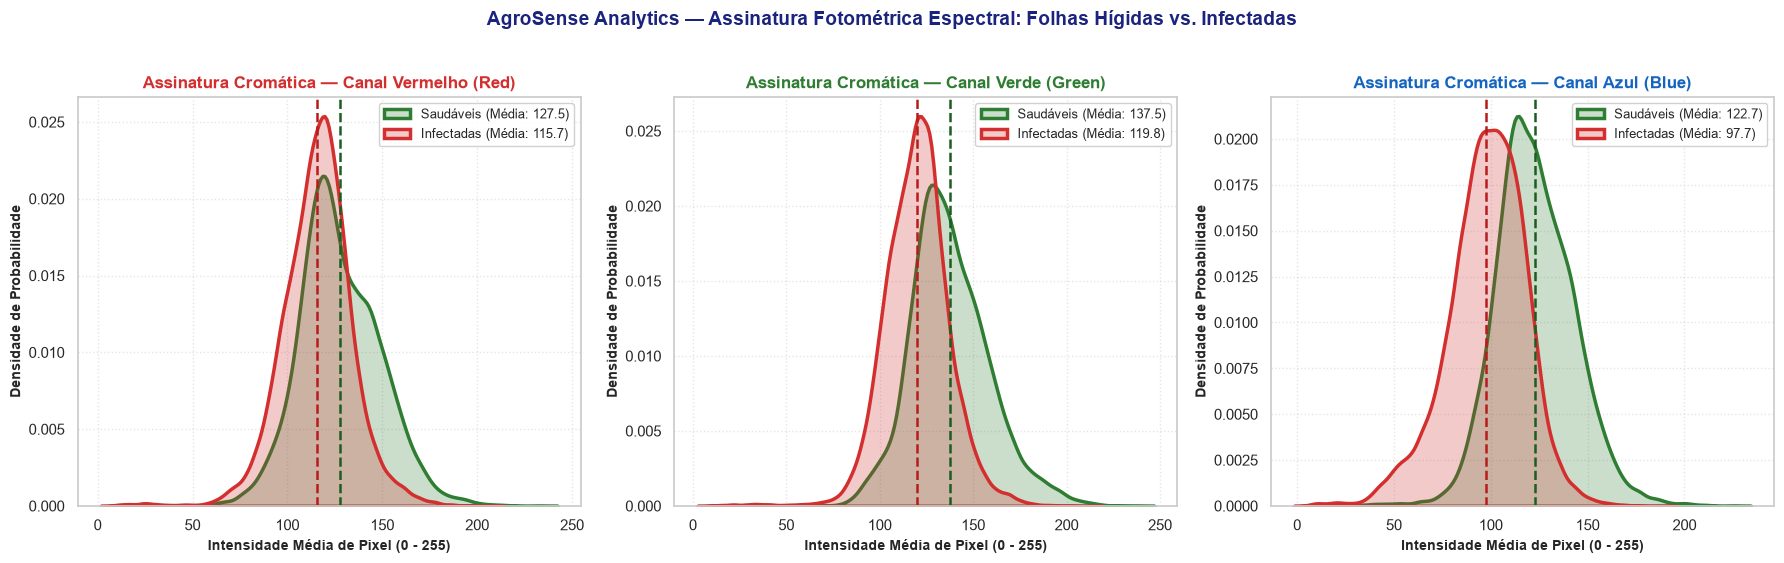

✓ Figura 4 salva com sucesso em: C:\Random\Aulas\Matérias\4º Semestre\Projeto aplicado 2\Etapa 3\reports\figures\eda_distribuicao_rgb.png (499.6 KB, 300 DPI)


In [6]:
# 6. Geração da Figura 4: Assinatura Fotométrica Espectral (RGB)
fig_path_4 = FIGURES_DIR / 'eda_distribuicao_rgb.png'

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

canais = [
    ('media_canal_r', 'Canal Vermelho (Red)', '#d32f2f'),
    ('media_canal_g', 'Canal Verde (Green)', '#2e7d32'),
    ('media_canal_b', 'Canal Azul (Blue)', '#1565c0')
]

saudaveis = df[df['is_saudavel'] == True]
doentes = df[df['is_saudavel'] == False]

for idx, (col, titulo, canal_cor) in enumerate(canais):
    v_h = saudaveis[col]
    v_d = doentes[col]
    
    sns.kdeplot(v_h, ax=axes[idx], color='#2e7d32', lw=2.5, label=f'Saudáveis (Média: {v_h.mean():.1f})', fill=True, alpha=0.25)
    sns.kdeplot(v_d, ax=axes[idx], color='#d32f2f', lw=2.5, label=f'Infectadas (Média: {v_d.mean():.1f})', fill=True, alpha=0.25)
    
    axes[idx].axvline(v_h.mean(), color='#1b5e20', linestyle='--', lw=1.8)
    axes[idx].axvline(v_d.mean(), color='#b71c1c', linestyle='--', lw=1.8)

    axes[idx].set_title(f'Assinatura Cromática — {titulo}', fontsize=12, fontweight='bold', color=canal_cor)
    axes[idx].set_xlabel('Intensidade Média de Pixel (0 - 255)', fontsize=10, fontweight='bold')
    axes[idx].set_ylabel('Densidade de Probabilidade', fontsize=10, fontweight='bold')
    axes[idx].legend(loc='upper right', fontsize=9.5, framealpha=0.9)
    axes[idx].grid(True, linestyle=':', alpha=0.5)

plt.suptitle('AgroSense Analytics — Assinatura Fotométrica Espectral: Folhas Hígidas vs. Infectadas',
             fontsize=14, fontweight='bold', y=1.02, color='#1a237e')
plt.tight_layout()
fig.savefig(fig_path_4, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"✓ Figura 4 salva com sucesso em: {fig_path_4} ({os.path.getsize(fig_path_4)/1024:.1f} KB, 300 DPI)")

---
## 7. Síntese Técnica e Justificativa de Engenharia de Dados

### Por que a tabela de metadados NÃO serve como entrada de modelo preditivo tabular?
Um erro conceitual comum em projetos de Visão Computacional é tentar alimentar modelos tabulares clássicos (como *Random Forest*, *XGBoost* ou *Regressão Logística*) com tabelas resumo de metadados extraídos de imagens (como médias e desvios de canais R, G e B, largura, altura ou tamanho em KB).

Na arquitetura do **AgroSense Analytics**, descartamos essa abordagem com base em três pilares formais de Ciência de Dados:

1. **Vazamento Determinístico de Alvo (*Target Leakage*):**
   - Atributos como `caminho_arquivo`, `nome_arquivo` e `especie_cultura` contêm substrings diretas da patologia (ex.: `Tomato___Early_blight`). Qualquer modelo tabular que utilize tais colunas aprenderia atalhos triviais (*spurious correlations*), alcançando 100% de acurácia espúria em treino e teste sem possuir capacidade real de generalização visual sobre novas fotos capturadas no campo.

2. **Colapso Irreversível da Topologia Espacial e Textura:**
   - A redução de uma matriz bidimensional de $256 \times 256$ pixels (composta por $65.536$ pontos de amostragem espacial por canal de cor) a meros valores escalares (média e desvio padrão global) destrói completamente:
     * O **formato geométrico das lesões** (ex.: halos concêntricos de *Target Spot* vs. pontuações dispersas de *Bacterial Spot*);
     * A **distribuição de bordas e gradientes espaciais**;
     * As **texturas fúngicas** e a localização relativa das pústulas sobre as nervuras.
   - Folhas de plantas completamente distintas infectadas por doenças diferentes podem apresentar a exata mesma média RGB global, tornando-as indistinguíveis no espaço de características puramente estatístico.

3. **Mandato da Modelagem Convolucional Profunda (*Deep CNN*):**
   - Redes Neurais Convolucionais profundas (como a **MobileNetV2**) operam diretamente sobre o tensor bruto de imagem $X \in \mathbb{R}^{3 \times 224 \times 224}$, preservando relações de invariância translacional e extraindo hierarquias de filtros espaciais — desde detectores de borda nas camadas iniciais até detectores morfológicos complexos de sintomas fitopatológicos nas camadas profundas.

Portanto, o arquivo `metadados_plantvillage.csv` cumpre a função estrita de **governança de dados, auditoria de catálogo e indexação de amostragem**, enquanto a inferência preditiva é delegada integralmente à esteira de Deep Learning desenvolvida nos Cadernos 02 e 03.

In [7]:
# 8. Verificação de Conformidade dos Artefatos Gerados no Notebook 01
print("=" * 70)
print("AUDITORIA DE ARTEFATOS MATERIALIZADOS — NOTEBOOK 01")
print("=" * 70)

required_artifacts = [
    DATA_DIR / 'metadados_plantvillage.csv',
    FIGURES_DIR / 'eda_distribuicao_classes.png',
    FIGURES_DIR / 'eda_status_sanitario.png',
    FIGURES_DIR / 'eda_mosaico_patologias.png',
    FIGURES_DIR / 'eda_distribuicao_rgb.png'
]

all_valid = True
for art in required_artifacts:
    if art.exists():
        size_kb = art.stat().st_size / 1024.0
        print(f"[OK] {art.name:32s} | Caminho: {art.relative_to(PROJECT_ROOT)} | Tamanho: {size_kb:8.1f} KB")
        if size_kb < 10.0:
            print(f"     [AVISO] Arquivo {art.name} com tamanho suspeito (< 10 KB)!")
            all_valid = False
    else:
        print(f"[FALHA] Artefato ausente: {art}")
        all_valid = False

print("=" * 70)
if all_valid:
    print("✓ TODOS OS ARTEFATOS DA ETAPA DE EDA FORAM CONSOLIDADOS COM SUCESSO!")
else:
    raise RuntimeError("Falha na geração dos artefatos da etapa de EDA!")

AUDITORIA DE ARTEFATOS MATERIALIZADOS — NOTEBOOK 01
[OK] metadados_plantvillage.csv       | Caminho: data\metadados_plantvillage.csv | Tamanho:  15835.9 KB
[OK] eda_distribuicao_classes.png     | Caminho: reports\figures\eda_distribuicao_classes.png | Tamanho:    848.1 KB
[OK] eda_status_sanitario.png         | Caminho: reports\figures\eda_status_sanitario.png | Tamanho:    293.9 KB
[OK] eda_mosaico_patologias.png       | Caminho: reports\figures\eda_mosaico_patologias.png | Tamanho:   1618.0 KB
[OK] eda_distribuicao_rgb.png         | Caminho: reports\figures\eda_distribuicao_rgb.png | Tamanho:    499.6 KB
✓ TODOS OS ARTEFATOS DA ETAPA DE EDA FORAM CONSOLIDADOS COM SUCESSO!
